# Labeling first-passage events with three barriers

Each event follows a side-adjusted return between a positive boundary, a negative boundary, and a final time:

$$
g_i(t)=s_i\left(\log P_t-\log P_{t_i}\right),\qquad
u_i=m_+\widehat\sigma_i,\qquad \ell_i=-m_-\widehat\sigma_i.
$$

Here, $t_i$ is event $i$ start time; $P_t$ is price; $s_i\in\{-1,1\}$ is the chosen side. $g_i(t)$ is the side-adjusted log return; $\widehat\sigma_i>0$ is the event scale; $m_+,m_-\geq0$ are boundary multipliers. $u_i$ is the upper boundary and $\ell_i$ is the lower boundary.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("06_financial_labels");
using CSV, Printf
using RiskLabAI.Data: daily_volatility_with_log_returns,symmetric_cusum_filter,cusum_filter_events_dynamic_threshold,vertical_barrier,triple_barrier,meta_labeling,calculate_t_value_linear_regression,find_trend_using_trend_scanning
raw = load_binance()
data_path = dataset_path("binance_btcusdt")
@assert isfile(data_path)
close_index,close_prices = raw.time,raw.close
log_price = log.(close_prices)
price_positions = Dict(time=>position for (position,time) in enumerate(close_index))
violet = "#C084FC"

function count_histogram!(figure,values,bins;color,label=false,alpha=.75)
    edges = collect(range(minimum(values),maximum(values);length=bins+1))
    counts = [count(value->edges[index]<=value && (value<edges[index+1] || index==bins && value==edges[end]),values) for index in 1:bins]
    bar!(figure,(edges[1:end-1].+edges[2:end])./2,counts;bar_width=diff(edges),color,fillalpha=alpha,linecolor=color,label)
    ylims!(figure,0.,1.1max(maximum(counts),last(ylims(figure))))
    return DataFrame(left=edges[1:end-1],right=edges[2:end],count=counts)
end

function box_summary!(figure,groups,colors)
    for (index,values) in enumerate(groups)
        lower,middle,upper = quantile(values,[.25,.5,.75])
        spread = upper-lower
        bottom = minimum(values[values.>=lower-1.5spread])
        top = maximum(values[values.<=upper+1.5spread])
        plot!(figure,Shape([index-.25,index+.25,index+.25,index-.25],[lower,lower,upper,upper]);color=colors[index],fillalpha=.65,linecolor=palette.text,label=false)
        plot!(figure,[index-.25,index+.25],[middle,middle];color=palette.text,label=false)
        plot!(figure,[index,index],[bottom,lower];color=palette.text,label=false)
        plot!(figure,[index,index],[upper,top];color=palette.text,label=false)
        for height in (bottom,top)
            plot!(figure,[index-.12,index+.12],[height,height];color=palette.text,label=false)
        end
    end
    return figure
end
span = 100
volatility = daily_volatility_with_log_returns(close_index,close_prices;span)
volatility_lookup = Dict(zip(volatility.index,volatility.volatility))

function dynamic_threshold_events(multiplier)
    selected = findall(isfinite,volatility.volatility)
    positions = [price_positions[volatility.index[index]] for index in selected]
    aligned = vcat(first(positions)-1,positions)
    return cusum_filter_events_dynamic_threshold(close_index[aligned],log_price[aligned],vcat(NaN,multiplier.*volatility.volatility[selected]))
end
event_times = dynamic_threshold_events(2.)
final_times = vertical_barrier(close_index,event_times,1)
final_lookup = Dict(zip(final_times.event,final_times.barrier))
event_times = [time for time in event_times if haskey(final_lookup,time) && isfinite(get(volatility_lookup,time,NaN))];


## Three Boundaries

In [2]:
function controlled_case(name,prices,expected_outcome)
    times = [DateTime(2020,1,1)+Minute(index-1) for index in eachindex(prices)]
    event = DataFrame(event_start=[first(times)],end_time=[last(times)],base_width=[.015],side=[1.])
    ending = only(triple_barrier(times,prices,event,(1.,1.)))
    realized = log(prices[findfirst(==(ending),times)]/first(prices))
    outcome = realized>.015 ? "Upper" : realized<-.015 ? "Lower" : "Time"
    return (;name,expected_outcome,outcome,ending,realized)
end
controlled_passages = DataFrame([controlled_case("Rising path",[100.,100.5,101.,102.,101.],"Upper"),controlled_case("Falling path",[100.,99.5,99.,98.,99.],"Lower"),controlled_case("Bounded path",[100.,100.2,99.9,100.1,100.],"Time")])
rename!(controlled_passages,["Path","Expected outcome","Observed outcome","First touch","Log return at touch"])
save_table(controlled_passages,paths,"controlled_first_passage";caption="Controlled price paths and their first touched boundaries.",label="tab:controlled-first-passage")


Row,Path,Expected outcome,Observed outcome,First touch,Log return at touch
,String,String,String,DateTime,Float64
1,Rising path,Upper,Upper,2020-01-01T00:03:00,0.0198026
2,Falling path,Lower,Lower,2020-01-01T00:03:00,-0.0202027
3,Bounded path,Time,Time,2020-01-01T00:04:00,0.0


## First-Passage Time

An event ends at the earliest upper crossing, lower crossing, or final allowed time:

$$
\tau_i=\min\left\{\inf\{t\geq t_i:g_i(t)>u_i\},\ \inf\{t\geq t_i:g_i(t)<\ell_i\},\ v_i\right\}.
$$

Here, $\tau_i$ is the ending time of event $i$; $t_i$ is its start; $g_i(t)$ is its side-adjusted return. $u_i$ and $\ell_i$ are the upper and lower boundaries; $v_i$ is the final time; $\inf$ selects the first qualifying time.

In [3]:
base_events = DataFrame(event_start=event_times,end_time=[final_lookup[time] for time in event_times],base_width=[volatility_lookup[time] for time in event_times])
completed_events = copy(base_events)
completed_events.end_time = triple_barrier(close_index,close_prices,base_events,(1.,1.))
labels = meta_labeling(completed_events,close_index,close_prices)
event_results = innerjoin(completed_events,select(labels,:event_start,:ret,:label);on=:event_start)
sort!(event_results,:event_start)
event_results.outcome = [row.ret>row.base_width ? "Upper" : row.ret < -row.base_width ? "Lower" : "Time" for row in eachrow(event_results)]
event_results.duration = Dates.value.(event_results.end_time.-event_results.event_start)./60000
outcome_rows,duration_rows = NamedTuple[],NamedTuple[]
for outcome in unique(event_results.outcome)
    part = event_results[event_results.outcome.==outcome,:]
    push!(outcome_rows,(;outcome,events=nrow(part),duration=median(part.duration),absolute_return=median(abs.(part.ret)),share=nrow(part)/nrow(event_results)))
end
for outcome in sort(unique(event_results.outcome))
    values = event_results.duration[event_results.outcome.==outcome]
    push!(duration_rows,(;outcome,lower=quantile(values,.1),middle=median(values),upper=quantile(values,.9)))
end
outcome_summary,duration_quantiles = DataFrame(outcome_rows),DataFrame(duration_rows)
rename!(outcome_summary,["Outcome","Events","Middle duration in minutes","Middle absolute log return","Share"])
rename!(duration_quantiles,["Outcome","10th percentile","Middle value","90th percentile"])
save_table(outcome_summary,paths,"triple_barrier_summary";caption="First-touch outcomes under equal volatility-scaled boundaries.",label="tab:triple-barrier-summary")
save_table(duration_quantiles,paths,"first_passage_duration";caption="First-passage duration quantiles in minutes.",label="tab:first-passage-duration")
save_data(base_events,paths,"base_barrier_events")
save_data(event_results,paths,"first_touch_event_results");


Row,Outcome,Events,Middle duration in minutes,Middle absolute log return,Share
,String,Int64,Float64,Float64,Float64
1,Lower,276,25.0,0.0101333,0.524715
2,Upper,250,23.5,0.0100991,0.475285


Row,Outcome,10th percentile,Middle value,90th percentile
,String,Float64,Float64,Float64
1,Lower,6.0,25.0,96.0
2,Upper,5.0,23.5,96.3


## Labels from the First Touch

The label records whether the upper or lower boundary was reached first, while a time ending uses the sign of the final return:

$$
y_i=\begin{cases}
1,&g_i(\tau_i)>u_i,\\
-1,&g_i(\tau_i)<\ell_i,\\
\operatorname{sign}\!\left(g_i(\tau_i)\right),&\tau_i=v_i.
\end{cases}
$$

Here, $y_i\in\{-1,0,1\}$ is the label; $g_i(\tau_i)$ is the return at the event ending time. $u_i$ and $\ell_i$ are the horizontal boundaries; $v_i$ is the final time; $\operatorname{sign}$ returns negative, zero, or positive direction.

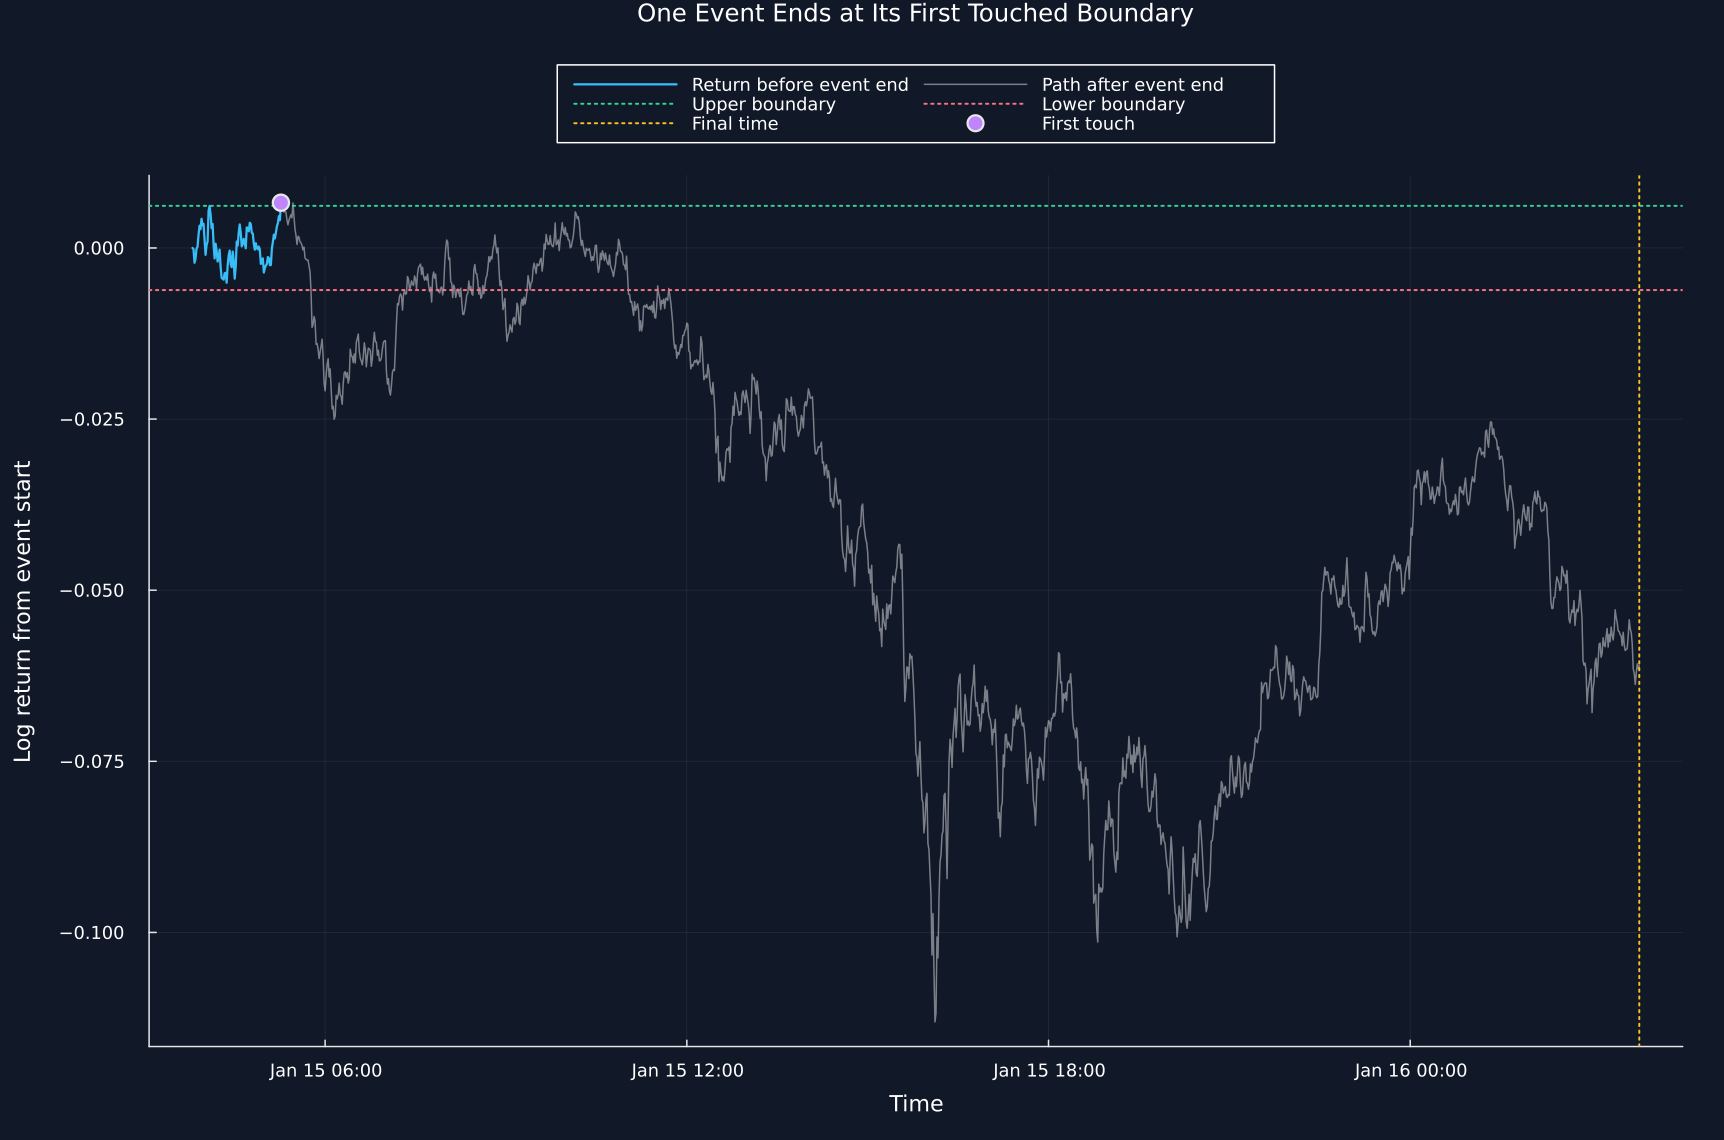

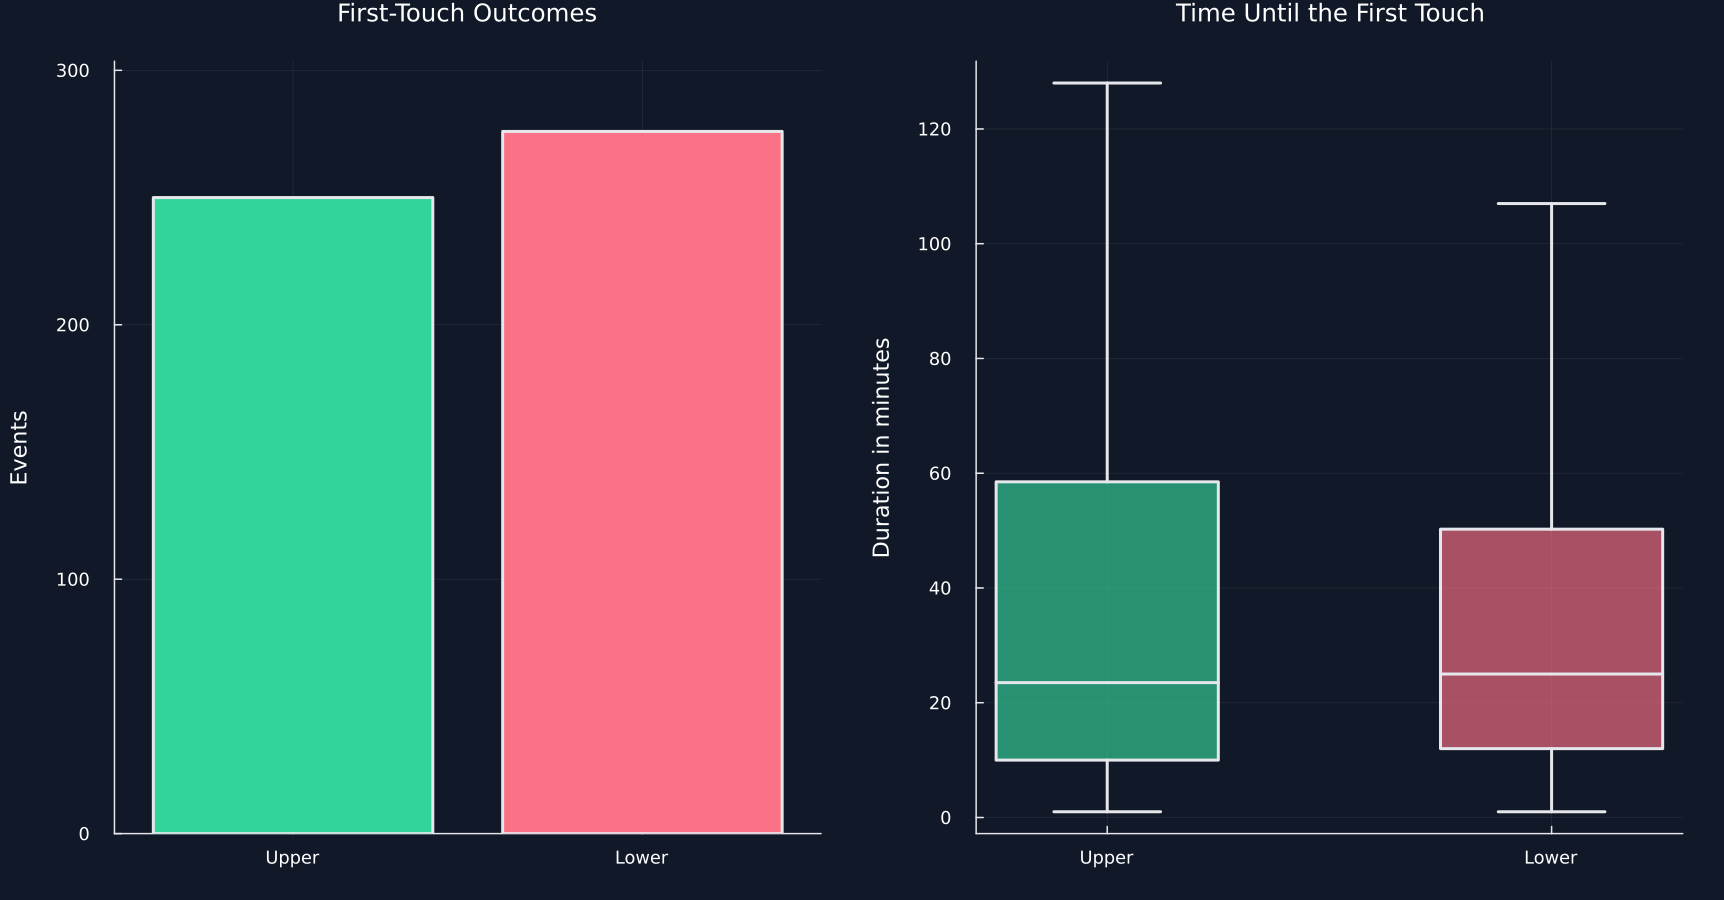

In [4]:
eligible = findall((event_results.outcome.!="Time").&(60 .<= event_results.duration .<= 720))
example_row = eligible[fld(length(eligible),2)+1]
example_start,example_end = event_results.event_start[example_row],event_results.end_time[example_row]
example_final,example_width = final_lookup[example_start],event_results.base_width[example_row]
selected_positions = price_positions[example_start]:price_positions[example_final]
example_times = close_index[selected_positions]
example_path = log.(close_prices[selected_positions]./close_prices[first(selected_positions)])
before,after = example_times.<=example_end,example_times.>=example_end
example_ticks = collect(ceil(example_start,Hour(6)):Hour(6):floor(example_final,Hour(6)))
figure = plot(example_times[before],example_path[before];color=palette.cyan,linewidth=1.5,label="Return before event end",xlabel="Time",ylabel="Log return from event start",title="One Event Ends at Its First Touched Boundary",legend=:outertop,legend_column=2,xticks=(example_ticks,Dates.format.(example_ticks,dateformat"u dd HH:MM")),size=(1150,760))
plot!(figure,example_times[after],example_path[after];color=palette.text,linewidth=1.,alpha=.5,label="Path after event end")
hline!(figure,[example_width];color=palette.green,linestyle=:dot,linewidth=1.3,label="Upper boundary")
hline!(figure,[-example_width];color=palette.rose,linestyle=:dot,linewidth=1.3,label="Lower boundary")
vline!(figure,[example_final];color=palette.amber,linestyle=:dot,linewidth=1.3,label="Final time")
scatter!(figure,[example_end],[example_path[findfirst(==(example_end),example_times)]];color=violet,markersize=6,label="First touch")
save_figure(figure,paths,"triple_barrier_first_touch")
save_data(DataFrame(time=example_times,log_return=example_path,event_end=fill(example_end,length(example_times)),width=fill(example_width,length(example_times))),paths,"example_first_touch_path")
outcome_order = [value for value in ["Upper","Lower","Time"] if value in event_results.outcome]
outcome_colors = Dict("Upper"=>palette.green,"Lower"=>palette.rose,"Time"=>palette.amber)
counts = [count(==(outcome),event_results.outcome) for outcome in outcome_order]
p1 = bar(outcome_order,counts;color=[outcome_colors[outcome] for outcome in outcome_order],ylabel="Events",title="First-Touch Outcomes",legend=false,ylims=(0.,1.1maximum(counts)))
groups = [event_results.duration[event_results.outcome.==outcome] for outcome in outcome_order]
p2 = plot(;xticks=(eachindex(outcome_order),outcome_order),ylabel="Duration in minutes",title="Time Until the First Touch",legend=false)
box_summary!(p2,groups,[outcome_colors[outcome] for outcome in outcome_order])
save_figure(plot(p1,p2;layout=(1,2),size=(1150,600)),paths,"first_touch_outcomes")


## Full-Sample Event View

Row,Outcome,Events,Mean log return,Return standard deviation,Middle log return,Smallest log return,Largest log return
,String,Int64,Float64,Float64,Float64,Float64,Float64
1,Lower,276,-0.0113077,0.00506266,-0.0101333,-0.0376397,-0.00351572
2,Upper,250,0.0114935,0.0059483,0.0100991,0.00260578,0.0339995


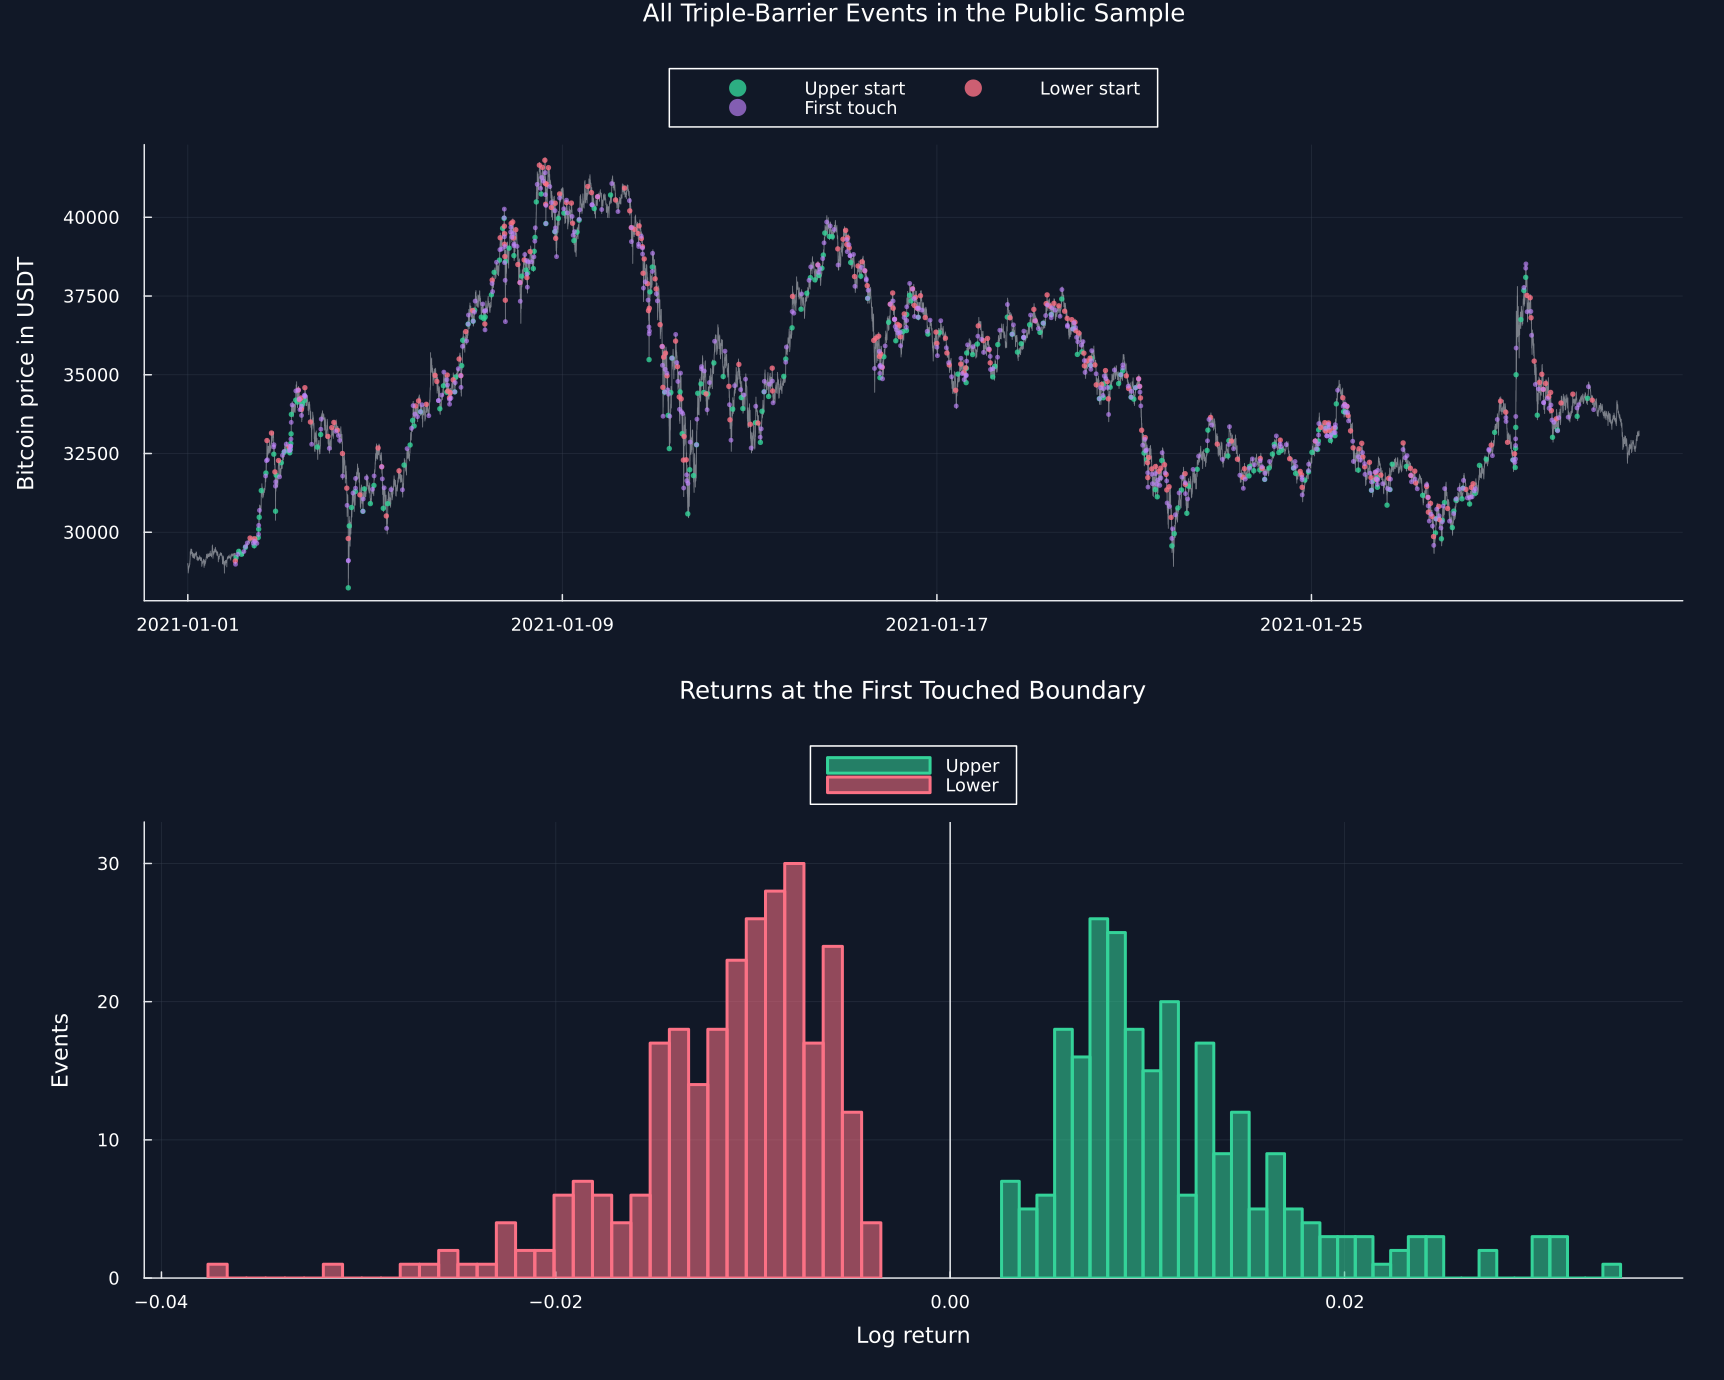

In [5]:
return_rows = NamedTuple[]
for outcome in sort(unique(event_results.outcome))
    values = event_results.ret[event_results.outcome.==outcome]
    push!(return_rows,(;outcome,events=length(values),average=mean(values),deviation=std(values),middle=median(values),smallest=minimum(values),largest=maximum(values)))
end
event_return_summary = DataFrame(return_rows)
rename!(event_return_summary,["Outcome","Events","Mean log return","Return standard deviation","Middle log return","Smallest log return","Largest log return"])
save_table(event_return_summary,paths,"event_return_summary";caption="Return summaries for all first-touch outcomes.",label="tab:chapter5-event-return-summary")
p1 = plot(close_index,close_prices;color=palette.text,linewidth=.55,alpha=.5,label=false,title="All Triple-Barrier Events in the Public Sample",ylabel="Bitcoin price in USDT",legend=:outertop,legend_column=2)
for outcome in outcome_order
    selected = event_results.event_start[event_results.outcome.==outcome]
    scatter!(p1,selected,[close_prices[price_positions[time]] for time in selected];color=outcome_colors[outcome],markersize=2,alpha=.8,markerstrokewidth=0,label=outcome*" start")
end
scatter!(p1,event_results.end_time,[close_prices[price_positions[time]] for time in event_results.end_time];color=violet,markersize=1.8,alpha=.65,markerstrokewidth=0,label="First touch")
p2 = plot(;title="Returns at the First Touched Boundary",xlabel="Log return",ylabel="Events",legend=:outertop)
for outcome in outcome_order
    values = event_results.ret[event_results.outcome.==outcome]
    histogram_data = count_histogram!(p2,values,35;color=outcome_colors[outcome],alpha=.55,label=outcome)
    save_data(histogram_data,paths,"first_touch_histogram_"*lowercase(outcome))
end
vline!(p2,[0.];color=palette.text,linewidth=1.,label=false)
save_figure(plot(p1,p2;layout=(2,1),size=(1150,920)),paths,"full_sample_barrier_events")


## Tests

In [6]:
function reference_first_touch(times,prices,events,multipliers)
    result = Union{Missing,DateTime}[]
    positions = Dict(time=>index for (index,time) in enumerate(times))
    for event in eachrow(events)
        start = positions[event.event_start]
        final = ismissing(event.end_time) ? last(times) : event.end_time
        candidates = ismissing(event.end_time) ? DateTime[] : [event.end_time]
        side = "side" in names(events) ? event.side : 1.
        upper = multipliers[1]>0 ? multipliers[1]*event.base_width : Inf
        lower = multipliers[2]>0 ? -multipliers[2]*event.base_width : -Inf
        for index in start:searchsortedlast(times,final)
            value = log(prices[index]/prices[start])*side
            if value>upper || value<lower
                push!(candidates,times[index])
                break
            end
        end
        push!(result,isempty(candidates) ? missing : minimum(candidates))
    end
    return result
end
random_generator = Xoshiro(11)
random_price_rows,random_event_rows = NamedTuple[],NamedTuple[]
for repetition in 1:25
    observation_count = rand(random_generator,60:299)
    times = [DateTime(2020,1,1)+Minute(index-1) for index in 1:observation_count]
    prices = 100cumprod(1 .+ .01randn(random_generator,observation_count))
    positions = sort(randperm(random_generator,observation_count-2)[1:rand(random_generator,3:24)])
    finals = Union{Missing,DateTime}[rand(random_generator)<.25 ? missing : times[min(position+rand(random_generator,1:29),observation_count)] for position in positions]
    events = DataFrame(event_start=times[positions],end_time=finals,base_width=.005 .+ .045rand(random_generator,length(positions)),side=rand(random_generator,[-1.,1.],length(positions)))
    multipliers = .5 .+ 1.5rand(random_generator,2)
    observed = triple_barrier(times,prices,events,multipliers)
    expected = reference_first_touch(times,prices,events,multipliers)
    @assert isequal(observed,expected)
    append!(random_price_rows,[(;repetition,time,price) for (time,price) in zip(times,prices)])
    append!(random_event_rows,[(;repetition,start=row.event_start,final=row.end_time,width=row.base_width,side=row.side,upper=first(multipliers),lower=last(multipliers),observed=observed[index]) for (index,row) in enumerate(eachrow(events))])
end
save_data(DataFrame(random_price_rows),paths,"random_barrier_prices")
save_data(DataFrame(random_event_rows),paths,"random_barrier_events")
@assert controlled_passages[!,"Expected outcome"] == controlled_passages[!,"Observed outcome"]
@assert nrow(event_results)>0
@assert all(.!ismissing.(event_results.end_time))
@assert all(event_results.end_time.<=[final_lookup[time] for time in event_results.event_start])
@assert all(event_results.ret[event_results.outcome.=="Upper"].>event_results.base_width[event_results.outcome.=="Upper"])
@assert all(event_results.ret[event_results.outcome.=="Lower"].< -event_results.base_width[event_results.outcome.=="Lower"])
@assert all(row.end_time==final_lookup[row.event_start] for row in eachrow(event_results) if row.outcome=="Time")
@assert issubset(Set(labels.label),Set([-1.,0.,1.]))
@assert sum(outcome_summary.Events)==nrow(event_results)
@assert isapprox(sum(outcome_summary.Share),1.)
@assert sum(event_return_summary.Events)==nrow(event_results)
@assert Set(event_return_summary.Outcome)==Set(event_results.outcome)
@assert isfile(joinpath(paths.figures,"full_sample_barrier_events.pdf"))
@assert isfile(joinpath(paths.tables,"event_return_summary.tex"))
